# Classificação GTA VI — trabalho acadêmico

Implementação exclusiva, sem modificar os demais notebooks ou a base original.

## 1. Auditoria de aderência e definição da tarefa

O CSV contém uma pesquisa tabular, não um corpus de comentários. `overall_sentiment` tem somente três classes. A tarefa é **classificar a nota de hype (`hype_score_1to10`)**, preservando as dez classes originais de 1 a 10. `primary_platform` passa a ser atributo categórico. A nota 1 tem somente dois registros: um no treino e outro no teste, sem suporte na validação. Nenhum rótulo é agrupado ou fabricado.

**Limitação obrigatória:** `most_anticipated_feature` contém dez descrições categóricas predefinidas, não texto livre. Aplicar TF-IDF a essas frases demonstra a técnica, mas NÃO transforma a base em texto genuinamente não estruturado. Portanto este trabalho é uma adaptação ao CSV solicitado, e não pode ser declarado integralmente aderente ao enunciado. Para entrega estrita, obter autorização do professor ou substituir/complementar a base por comentários reais associados aos registros, com origem e licença verificáveis. Nenhum texto sintético foi criado.

O alvo e `respondent_id` são excluídos de X. Os demais campos são respostas disponíveis no mesmo questionário: trata-se de associação contemporânea, não previsão temporal ou causal. `overall_sentiment` permanece como atributo contemporâneo correlato ao hype; sem proveniência da coleta, não se pode descartar que seja derivado da nota. Não interpretamos este protocolo como previsão antecipada; uso em produção exige verificar a origem e disponibilidade desse campo. Não há informação no arquivo que comprove origem, licença, representatividade ou coleta real; não assumimos esses fatos.

## Roteiro

Estudo introdutório → divisão estratificada 60/20/20 → TF-IDF e atributos estruturados → CART própria → LR via SGD com quatro penalidades → consistência 30/60/90% → cinco curvas → seleção somente pela validação → teste de todos os casos → três matrizes de confusão → conclusões e exportação.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import time
import numpy as np
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
import sklearn
import scipy
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.linear_model import SGDClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

# Funciona com execução iniciada na raiz ou na pasta notebooks.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'datasets/gta6_fan_expectations_2026.csv').is_file())
DATASET = ROOT / 'datasets/gta6_fan_expectations_2026.csv'
OUT = ROOT / 'docs/gta6_classificacao/resultados'
FIG = OUT / 'figuras'
FIG.mkdir(parents=True, exist_ok=True)
TARGET = 'hype_score_1to10'
SEED = 42
SEEDS = [42, 43, 44]
FRACTIONS = [0.10, 0.30, 0.60, 0.90, 1.00]
MAX_DEPTH = 12
EPOCHS = 160
VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scikit_learn': sklearn.__version__,
            'scipy': scipy.__version__}
print(VERSIONS)
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.grid': True})
df = pd.read_csv(DATASET)
assert len(df) >= 2000
assert df[TARGET].nunique() >= 5
assert not df[TARGET].isna().any()
assert df.respondent_id.is_unique
CLASSES = np.sort(df[TARGET].unique())
print('Dimensões:', df.shape, '\nClasses:', CLASSES)
display(df.head())

{'python': '3.14.4', 'numpy': '2.5.2', 'pandas': '3.0.5', 'scikit_learn': '1.9.0', 'scipy': '1.18.1'}
Dimensões: (6000, 20) 
Classes: [ 1  2  3  4  5  6  7  8  9 10]


,respondent_id,age,gender,region,primary_platform,favorite_previous_gta,years_following_gta6,primary_info_source,trailer1_times_watched,most_anticipated_feature,hype_score_1to10,confidence_rockstar_delivers_1to5,preorder_intent,willingness_to_pay_usd,expected_firstweek_hours,expects_release_delay,worried_about_price,follows_rockstar_socials,hype_change_vs_6mo_ago,overall_sentiment
0,R100000,30,Male,Europe,Undecided,GTA San Andreas,5,Reddit,13,Better driving physics,10,5,No,96.0,19,Yes,No,Yes,Same,Very Positive
1,R100001,29,Male,Europe,PC,GTA San Andreas,4,X/Twitter,15,Dual protagonists (Jason & Lucia),10,3,Yes,70.0,10,No,No,No,Same,Very Positive
2,R100002,28,Female,Europe,Xbox Series X/S,GTA V,6,YouTube,9,Story & narrative depth,7,5,Maybe,81.0,6,No,No,Yes,Increased,Positive
3,R100003,30,Male,Europe,Xbox Series X/S,GTA Vice City,8,Gaming news sites,6,Online/multiplayer mode,8,4,Yes,80.0,11,Yes,No,Yes,Increased,Very Positive
4,R100004,40,Male,Europe,PlayStation 5,GTA V,10,TikTok,8,Realistic economy & businesses,8,4,No,69.0,25,Yes,Yes,No,Same,Very Positive


## 2. Estudo introdutório

Cada linha corresponde a um identificador de respondente. A análise abaixo registra tipos, cardinalidade, ausências, duplicações, estatísticas numéricas, distribuição de notas de hype, sentimentos e descrições. O estudo descritivo do arquivo completo não ajusta modelos nem hiperparâmetros. As análises relacionais posteriores usam apenas treino.

Frases repetidas são esperadas por serem opções do questionário; não devem ser confundidas com registros duplicados. A faixa de idade e os anos acompanhando GTA VI também merecem cautela: não inferimos autenticidade dos respondentes a partir dessas variáveis.

,tipo,valores_unicos,ausentes,ausentes_pct
respondent_id,str,6000,0,0.0
age,int64,43,0,0.0
gender,str,4,60,1.0
region,str,6,0,0.0
primary_platform,str,5,0,0.0
favorite_previous_gta,str,7,0,0.0
years_following_gta6,int64,14,0,0.0
primary_info_source,str,8,0,0.0
trailer1_times_watched,int64,21,0,0.0
most_anticipated_feature,str,10,0,0.0


,count,mean,std,min,25%,50%,75%,max
age,6000.0,26.120500,7.665210,13.0,20.0,26.0,31.0,59.0
years_following_gta6,6000.0,6.030833,2.911751,0.0,4.0,6.0,8.0,13.0
trailer1_times_watched,6000.0,8.785333,3.032675,0.0,7.0,9.0,11.0,20.0
hype_score_1to10,6000.0,7.777500,1.797832,1.0,7.0,8.0,9.0,10.0
confidence_rockstar_delivers_1to5,6000.0,3.700667,0.970854,1.0,3.0,4.0,4.0,5.0
willingness_to_pay_usd,5880.0,71.691497,16.133165,6.0,61.0,72.0,83.0,120.0
expected_firstweek_hours,6000.0,16.451000,11.491937,0.0,8.0,14.0,22.0,101.0


Linhas duplicadas: 0
Respostas duplicadas sem ID: 0


,quantidade
overall_sentiment,
Very Positive,3528
Positive,2190
Neutral/Cautious,282


,quantidade
most_anticipated_feature,
Open-world Vice City map,954
Dual protagonists (Jason & Lucia),905
Story & narrative depth,718
Online/multiplayer mode,643
Realistic economy & businesses,548
Map size & exploration,527
Improved police/AI systems,466
Deeper character customization,434
Graphics & ray tracing,424


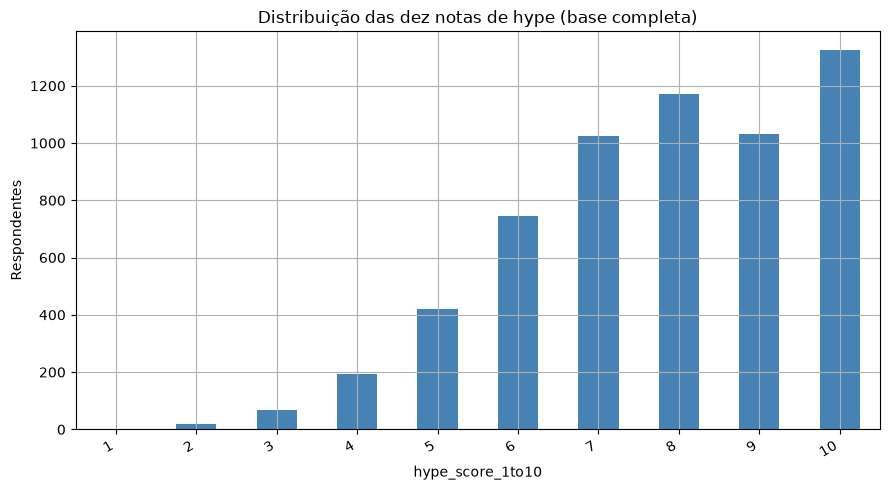

In [2]:
schema = pd.DataFrame({'tipo': df.dtypes.astype(str), 'valores_unicos': df.nunique(),
                       'ausentes': df.isna().sum(), 'ausentes_pct': df.isna().mean() * 100})
display(schema)
display(df.describe().T)
print('Linhas duplicadas:', int(df.duplicated().sum()))
print('Respostas duplicadas sem ID:', int(df.drop(columns='respondent_id').duplicated().sum()))
display(df.overall_sentiment.value_counts().rename('quantidade').to_frame())
display(df.most_anticipated_feature.value_counts().rename('quantidade').to_frame())
class_counts = df[TARGET].value_counts().reindex(CLASSES)
fig, ax = plt.subplots()
class_counts.plot.bar(ax=ax, color='steelblue')
ax.set(title='Distribuição das dez notas de hype (base completa)', ylabel='Respondentes')
plt.xticks(rotation=30, ha='right'); plt.tight_layout()
fig.savefig(FIG / 'eda_classes.png', dpi=150)
plt.show()
schema.to_csv(OUT / 'auditoria_colunas.csv')
class_counts.rename('quantidade').to_csv(OUT / 'distribuicao_classes.csv')

## 3. Partições e proteção contra vazamento

Reservamos primeiro 20% para teste. Dos 80% restantes, 25% ficam para validação: 20% do total, restando 60% para treino. Estratificação pelo alvo nas classes com suporte suficiente, semente 42 e verificação de conjuntos disjuntos. Exceção explícita: dos dois registros de nota 1, um vai ao treino e outro ao teste; não há nota 1 na validação. Nenhuma linha é descartada ou duplicada. F1 macro usa sempre as dez classes e atribui zero à classe sem suporte na validação. O teste fica intocado até a seleção estar congelada.

Os tamanhos 30%, 60% e 90% se referem EXCLUSIVAMENTE aos 60% de treino: 18%, 36% e 54% do total. Para cada semente, os subconjuntos são estratificados e aninhados: 30% ⊂ 60% ⊂ 90%. A divisão principal é fixa; as repetições medem sensibilidade à amostragem/SGD, não são validação cruzada e não oferecem intervalos populacionais de confiança.

In [3]:
# Classes com dois registros não podem ocupar três partições disjuntas.
rare = df[df[TARGET].map(df[TARGET].value_counts()) < 3]
common = df.drop(index=rare.index)
rare_train = rare.groupby(TARGET, group_keys=False).sample(n=1, random_state=SEED)
rare_test = rare.drop(index=rare_train.index)
train_val, common_test = train_test_split(
    common, test_size=1200 - len(rare_test), stratify=common[TARGET], random_state=SEED)
common_train, val = train_test_split(
    train_val, test_size=1200, stratify=train_val[TARGET], random_state=SEED)
train = pd.concat([common_train, rare_train]).sample(frac=1, random_state=SEED)
test = pd.concat([common_test, rare_test]).sample(frac=1, random_state=SEED)
assert (len(train), len(val), len(test)) == (3600, 1200, 1200)
sets = [set(frame.respondent_id) for frame in [train, val, test]]
assert not sets[0] & sets[1] and not sets[0] & sets[2] and not sets[1] & sets[2]
assert set.union(*sets) == set(df.respondent_id)
split_table = pd.DataFrame({name: frame[TARGET].value_counts().reindex(CLASSES, fill_value=0)
                           for name, frame in [('treino', train), ('validacao', val), ('teste', test)]})
display(split_table)
split_table.to_csv(OUT / 'particoes_por_classe.csv')
pd.concat([frame[['respondent_id']].assign(particao=name)
           for name, frame in [('treino', train), ('validacao', val), ('teste', test)]]
          ).to_csv(OUT / 'particoes_ids.csv', index=False)
FEATURES = [c for c in df if c not in [TARGET, 'respondent_id']]
assert TARGET not in FEATURES and 'respondent_id' not in FEATURES
X_train, y_train = train[FEATURES], train[TARGET].to_numpy()
X_val, y_val = val[FEATURES], val[TARGET].to_numpy()
# Não preparar X_test nem predizer teste nesta fase.

# Interpretação descritiva limitada ao treino.
display(pd.crosstab(train.most_anticipated_feature, train[TARGET], normalize='index').round(3))


def subconjuntos_aninhados(frame, seed):
    pools = {1.0: frame}
    current = frame
    for fraction in sorted([f for f in FRACTIONS if f < 1], reverse=True):
        # Alocação proporcional com mínimo de um exemplo por classe.
        # Preserva a classe rara em todos os subconjuntos, sem duplicá-la.
        counts = current[TARGET].value_counts().reindex(CLASSES)
        size = int(round(len(frame) * fraction))
        desired = counts.to_numpy() * size / len(current)
        allocated = np.maximum(1, np.floor(desired).astype(int))
        while allocated.sum() != size:
            if allocated.sum() < size:
                deficits = np.where(allocated < counts.to_numpy(), desired - allocated, -np.inf)
                allocated[np.argmax(deficits)] += 1
            else:
                excess = np.where(allocated > 1, allocated - desired, -np.inf)
                allocated[np.argmax(excess)] -= 1
        current = pd.concat([current[current[TARGET] == label].sample(n=int(n), random_state=seed)
                             for label, n in zip(CLASSES, allocated)])
        pools[fraction] = current
    for small, large in zip(FRACTIONS[:-1], FRACTIONS[1:]):
        assert set(pools[small].respondent_id) <= set(pools[large].respondent_id)
    for fraction, sample in pools.items():
        assert len(sample) == round(len(frame) * fraction)
        assert set(sample[TARGET]) == set(CLASSES)
    return pools

POOLS = {seed: subconjuntos_aninhados(train, seed) for seed in SEEDS}
size_table = pd.DataFrame([{'fracao_treino': f, 'n_treino': len(POOLS[42][f]),
                           'fracao_total': len(POOLS[42][f]) / len(df)} for f in FRACTIONS])
display(size_table)
size_table.to_csv(OUT / 'tamanhos_treino.csv', index=False)
pd.concat([sample[['respondent_id']].assign(semente=seed, fracao_treino=fraction)
           for seed, pools in POOLS.items() for fraction, sample in pools.items()]
         ).to_csv(OUT / 'subconjuntos_ids.csv', index=False)

,treino,validacao,teste
hype_score_1to10,,,
1,1,0,1
2,11,4,4
3,41,14,14
4,116,38,38
5,251,84,84
6,448,149,149
7,615,205,205
8,703,235,234
9,620,206,206


hype_score_1to10,1,2,3,4,5,6,7,8,9,10
most_anticipated_feature,,,,,,,,,,
Better driving physics,0.000,0.013,0.009,0.039,0.073,0.146,0.150,0.167,0.172,0.232
Deeper character customization,0.000,0.000,0.016,0.039,0.058,0.125,0.140,0.222,0.163,0.237
Dual protagonists (Jason & Lucia),0.000,0.000,0.004,0.034,0.060,0.116,0.155,0.224,0.160,0.248
Graphics & ray tracing,0.000,0.004,0.004,0.020,0.061,0.143,0.197,0.184,0.172,0.213
Improved police/AI systems,0.000,0.007,0.011,0.039,0.068,0.089,0.171,0.224,0.157,0.235
Map size & exploration,0.000,0.006,0.025,0.040,0.058,0.117,0.182,0.188,0.154,0.231
Online/multiplayer mode,0.000,0.005,0.005,0.023,0.081,0.140,0.186,0.163,0.178,0.219
Open-world Vice City map,0.002,0.000,0.014,0.036,0.078,0.116,0.173,0.182,0.189,0.211
Realistic economy & businesses,0.000,0.000,0.006,0.032,0.076,0.152,0.190,0.194,0.168,0.181


,fracao_treino,n_treino,fracao_total
0,0.1,360,0.06
1,0.3,1080,0.18
2,0.6,2160,0.36
3,0.9,3240,0.54
4,1.0,3600,0.60


## 4. Representação TF-IDF + dados estruturados

Para termo t no documento d: TF sublinear = 1 + log(contagem), IDF suavizado = log((1+n)/(1+df(t))) + 1. O produto é normalizado pela norma L2 do documento. Usamos unigramas e bigramas das frases originais, sem tradução, sem concatenar alvo e sem fabricar comentários.

As variáveis numéricas recebem imputação pela mediana e padronização; categorias recebem uma categoria de ausência e one-hot com categorias desconhecidas ignoradas. **Cada subconjunto ajusta seu próprio pré-processador**, incluindo vocabulário e IDF, medianas, médias, desvios e categorias. A mesma representação é fornecida à LR e à AD. TF-IDF de dez frases tem diversidade limitada e funciona principalmente como representação lexical de categorias.

Referências oficiais: [TF-IDF](https://scikit-learn.org/stable/modules/feature_extraction.html#tfidf-term-weighting) e [prevenção de vazamento](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

In [4]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def criar_preprocessador(frame):
    """Ajustar SOMENTE no subconjunto de treino de cada experimento."""
    numeric = frame.select_dtypes(include='number').columns.tolist()
    categorical = [c for c in frame.columns if c not in numeric and c != 'most_anticipated_feature']
    transformers = [('texto', TfidfVectorizer(ngram_range=(1, 2), lowercase=True,
                     sublinear_tf=True, smooth_idf=True, norm='l2', min_df=1),
                     'most_anticipated_feature')]
    if numeric:
        transformers.append(('numericos', Pipeline([
            ('imputar', SimpleImputer(strategy='median')),
            ('escala', StandardScaler())]), numeric))
    if categorical:
        transformers.append(('categoricos', Pipeline([
            ('imputar', SimpleImputer(strategy='constant', fill_value='Ausente')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical))
    return ColumnTransformer(transformers, sparse_threshold=1.0)


In [5]:
processor_demo = criar_preprocessador(X_train)
Z_demo = processor_demo.fit_transform(X_train)
vocab = processor_demo.named_transformers_['texto']
display(pd.DataFrame({'termo': vocab.get_feature_names_out(), 'idf': vocab.idf_}).head(20))
print('Atributos combinados:', Z_demo.shape[1], 'Vocabulário TF-IDF:', len(vocab.vocabulary_))
print('Exemplos de frases originais:', X_train.most_anticipated_feature.head(3).tolist())

,termo,idf
0,ai,3.547060
1,ai systems,3.547060
2,better,3.733646
3,better driving,3.733646
4,businesses,3.433225
5,character,3.636007
6,character customization,3.636007
7,city,2.827664
8,city map,2.827664
9,customization,3.636007


Atributos combinados: 109 Vocabulário TF-IDF: 57
Exemplos de frases originais: ['Dual protagonists (Jason & Lucia)', 'Dual protagonists (Jason & Lucia)', 'Dual protagonists (Jason & Lucia)']


## 5. Árvore de decisão implementada do zero

CART binária multiclasse com Gini = 1 − Σ p(k)². Em cada nó, ordena cada atributo, examina TODOS os pontos médios entre valores distintos, calcula Gini ponderado dos filhos com contagens cumulativas e escolhe a maior redução. Não chama `sklearn.tree` para treinamento ou predição.

Paradas: pureza, altura máxima, mínimo de amostras para dividir, mínimo por folha ou ganho insuficiente. Uma folha armazena proporções de classes; a predição percorre cortes até a folha e usa argmax. Empates são determinísticos. Raiz tem profundidade zero. Há teste de treino/predição multiclasse, matriz esparsa, classe única, empate, limite de altura, ausência de ajuste e entradas inválidas.

Por simplicidade didática, somente a árvore converte a matriz combinada para densa; o tamanho desta base torna isso viável. A busca é exata, não uma aproximação por quantis. Uma ordenação custa O(p n log n) por nó; a versão didática não é indicada para corpus com dezenas de milhares de atributos.

In [6]:
import numpy as np
from scipy import sparse


class ArvoreDecisaoPropria:
    """CART multiclasse: busca exata de cortes, Gini e predição próprias.

    Raiz na profundidade zero. Empates: menor índice de atributo/corte/classe.
    Não utiliza sklearn.tree. Conversão densa é limitada a esta base pequena.
    """

    def __init__(self, max_depth=12, min_samples_leaf=8, min_samples_split=2,
                 min_impurity_decrease=1e-10):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.min_samples_split = min_samples_split
        self.min_impurity_decrease = min_impurity_decrease

    @staticmethod
    def _matrix(X):
        X = X.toarray() if sparse.issparse(X) else np.asarray(X, dtype=float)
        if X.ndim != 2 or not np.isfinite(X).all():
            raise ValueError('X deve ser matriz 2D finita, previamente imputada')
        return X

    def fit(self, X, y):
        X = self._matrix(X)
        y = np.asarray(y)
        if y.ndim != 1 or len(y) != len(X) or len(y) == 0:
            raise ValueError('y deve ser vetor não vazio alinhado a X')
        if self.max_depth < 0 or self.min_samples_leaf < 1 or self.min_samples_split < 2:
            raise ValueError('Parâmetros de profundidade/amostras inválidos')
        self.classes_, encoded = np.unique(y, return_inverse=True)
        self.n_features_in_ = X.shape[1]
        self.n_classes_ = len(self.classes_)
        self.node_count_ = 0
        self.depth_ = 0
        self.feature_importances_ = np.zeros(self.n_features_in_)
        self.root_ = self._grow(X, encoded, 0, len(y))
        total = self.feature_importances_.sum()
        if total > 0:
            self.feature_importances_ /= total
        return self

    def _grow(self, X, y, depth, n_total):
        self.node_count_ += 1
        self.depth_ = max(self.depth_, depth)
        n = len(y)
        counts = np.bincount(y, minlength=self.n_classes_)
        impurity = 1.0 - np.sum((counts / n) ** 2)
        node = {'proba': counts / n, 'depth': depth, 'samples': n,
                'gini': impurity, 'feature': None}
        if (depth >= self.max_depth or impurity <= 1e-15
                or n < max(self.min_samples_split, 2 * self.min_samples_leaf)):
            return node
        best_gain = self.min_impurity_decrease
        best = None
        # Todas as fronteiras entre valores distintos são avaliadas.
        for feature in range(X.shape[1]):
            order = np.argsort(X[:, feature], kind='stable')
            values = X[order, feature]
            positions = np.flatnonzero(values[:-1] < values[1:]) + 1
            positions = positions[(positions >= self.min_samples_leaf)
                                  & (n - positions >= self.min_samples_leaf)]
            if not len(positions):
                continue
            cumulative = np.cumsum(np.eye(self.n_classes_)[y[order]], axis=0)
            left = cumulative[positions - 1]
            right = counts - left
            # Gini ponderado = 1 - (sum(L_k²)/nL + sum(R_k²)/nR)/n.
            weighted = 1 - (np.sum(left ** 2, axis=1) / positions
                            + np.sum(right ** 2, axis=1) / (n - positions)) / n
            gains = impurity - weighted
            i = int(np.argmax(gains))
            if gains[i] > best_gain + 1e-14:
                pos = int(positions[i])
                a, b = float(values[pos - 1]), float(values[pos])
                # Evita overflow com sinais opostos e arredondamento para b.
                threshold = a / 2 + b / 2 if a < 0 < b else a + (b - a) / 2
                if not a <= threshold < b:
                    threshold = a
                best_gain = float(gains[i])
                best = feature, float(threshold)
        if best is None:
            return node
        feature, threshold = best
        mask = X[:, feature] <= threshold
        self.feature_importances_[feature] += n / n_total * best_gain
        node.update(feature=feature, threshold=threshold,
                    left=self._grow(X[mask], y[mask], depth + 1, n_total),
                    right=self._grow(X[~mask], y[~mask], depth + 1, n_total))
        return node

    def predict_proba(self, X):
        if not hasattr(self, 'root_'):
            raise ValueError('Treine a árvore antes da predição')
        X = self._matrix(X)
        if X.shape[1] != self.n_features_in_:
            raise ValueError('Quantidade de atributos diferente do treino')
        probabilities = np.empty((len(X), self.n_classes_))
        for i, row in enumerate(X):
            node = self.root_
            while node['feature'] is not None:
                node = node['left'] if row[node['feature']] <= node['threshold'] else node['right']
            probabilities[i] = node['proba']
        return probabilities

    def predict(self, X):
        probabilities = self.predict_proba(X)
        return self.classes_[np.argmax(probabilities, axis=1)]


## 6. Regressão logística por gradiente descendente estocástico

`SGDClassifier(loss="log_loss")` implementa regressão logística por SGD, uma variante de gradient descent. Multiclasse via um-contra-resto (OvR), não softmax multinomial. Caso o professor exija especificamente GD em lote, esta variante precisa ser confirmada. `LogisticRegression` com solver padrão não será apresentado incorretamente como GD.

Sem penalidade, Ridge/L2, Lasso/L1 e Elastic Net (50% L1 / 50% L2). Objetivo binário: média da perda logística + alpha × penalidade; L2 = ||w||²/2, L1 = ||w||₁, Elastic Net = (1−r)||w||²/2 + r||w||₁. Não são `RidgeClassifier` ou `Lasso` de regressão linear.

Configuração pré-fixada: alpha=0,001 nas variantes regularizadas; taxa inicial 0,01, decaimento inverso com potência 0,25, 160 épocas, média dos pesos, sem parada por validação e sem busca de hiperparâmetros. Sem balanceamento artificial das classes, para comparação com a distribuição observada e baseline majoritário. O valor de alpha não foi otimizado e pode afetar o resultado. As épocas são passagens pelo subconjunto, não o eixo X das curvas; X na LR é quantidade de exemplos.

[Documentação oficial de SGDClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDClassifier.html).

In [7]:
PENALTIES = {'LR sem regularizacao': None, 'LR Ridge': 'l2',
             'LR Lasso': 'l1', 'LR Elastic Net': 'elasticnet'}


def treinar_lr(Z, y, family, seed):
    penalty = PENALTIES[family]
    model = SGDClassifier(loss='log_loss', penalty=penalty,
                          alpha=0.0 if penalty is None else 0.001, l1_ratio=0.5,
                          learning_rate='invscaling', eta0=0.01, power_t=0.25,
                          average=True, shuffle=False, random_state=seed,
                          early_stopping=False, n_jobs=1)
    rng = np.random.default_rng(seed)
    for epoch in range(EPOCHS):
        order = rng.permutation(len(y))
        model.partial_fit(Z[order], y[order], classes=CLASSES)
    return model


def metricas(y, prediction):
    scores = {'accuracy': accuracy_score(y, prediction)}
    for avg in ['micro', 'macro', 'weighted']:
        scores[f'precision_{avg}'] = precision_score(y, prediction, labels=CLASSES, average=avg, zero_division=0)
        scores[f'recall_{avg}'] = recall_score(y, prediction, labels=CLASSES, average=avg, zero_division=0)
        scores[f'f1_{avg}'] = f1_score(y, prediction, labels=CLASSES, average=avg, zero_division=0)
    return scores


records, fitted = [], {}


def registrar(model, processor, sample, family, seed, fraction, kind, depth=None):
    key = f'{kind}|{family}|seed={seed}|fraction={fraction}|depth={depth}'
    Z = processor.transform(sample[FEATURES])
    metadata = {'modelo_id': key, 'familia': family, 'semente': seed,
                'fracao_treino': fraction, 'n_treino': len(sample),
                'experimento': kind, 'max_depth': depth}
    train_metrics = metricas(sample[TARGET], model.predict(Z))
    val_metrics = metricas(y_val, model.predict(processor.transform(X_val)))
    row = dict(metadata, **{'treino_' + k: v for k, v in train_metrics.items()},
               **{'validacao_' + k: v for k, v in val_metrics.items()})
    if family == 'AD propria':
        row.update(altura_real=model.depth_, nos=model.node_count_)
    else:
        row['coeficientes_zero_pct'] = float(np.mean(model.coef_ == 0) * 100)
    records.append(row)
    fitted[key] = (model, processor)
    return key

# Todas as LR das curvas são treinadas de forma independente; nada de warm-start
# entre tamanhos/penalidades. Pré-processadores são reutilizados apenas dentro
# do MESMO subconjunto e semente, pois esse ajuste é independente do estimador.
start = time.perf_counter()
for seed in SEEDS:
    for fraction in FRACTIONS:
        sample = POOLS[seed][fraction]
        processor = criar_preprocessador(sample[FEATURES])
        Z = processor.fit_transform(sample[FEATURES])
        y = sample[TARGET].to_numpy()
        for family in PENALTIES:
            model = treinar_lr(Z, y, family, seed)
            registrar(model, processor, sample, family, seed, fraction, 'curva_lr')
        # Consistência da AD com configuração FIXA, escolhida antes dos resultados.
        if fraction in [0.30, 0.60, 0.90]:
            tree = ArvoreDecisaoPropria(max_depth=8, min_samples_leaf=8).fit(Z, y)
            registrar(tree, processor, sample, 'AD propria', seed, fraction, 'consistencia_ad', 8)
    print('Semente concluída:', seed)

# Curva de complexidade: mesma base de treino, profundidades 1 até altura limite 12.
processor_tree = criar_preprocessador(X_train)
Z_tree = processor_tree.fit_transform(X_train)
for depth in range(1, MAX_DEPTH + 1):
    tree = ArvoreDecisaoPropria(max_depth=depth, min_samples_leaf=8).fit(Z_tree, y_train)
    registrar(tree, processor_tree, train, 'AD propria', SEED, 1.0, 'curva_ad', depth)
results = pd.DataFrame(records)
results['gap_f1_macro'] = results.treino_f1_macro - results.validacao_f1_macro
assert len(results) == 81 and results.modelo_id.is_unique
results.to_csv(OUT / 'treino_validacao_todos_casos.csv', index=False)
print('Modelos treinados:', len(results), 'Tempo (s):', round(time.perf_counter() - start, 2))
display(results.head())

Semente concluída: 42


Semente concluída: 43


Semente concluída: 44


Modelos treinados: 81 Tempo (s): 301.78


,modelo_id,familia,semente,fracao_treino,n_treino,experimento,max_depth,treino_accuracy,treino_precision_micro,treino_recall_micro,...,validacao_precision_macro,validacao_recall_macro,validacao_f1_macro,validacao_precision_weighted,validacao_recall_weighted,validacao_f1_weighted,coeficientes_zero_pct,altura_real,nos,gap_f1_macro
0,curva_lr|LR sem regularizacao|seed=42|fraction...,LR sem regularizacao,42,0.1,360,curva_lr,NaN,0.622222,0.622222,0.622222,...,0.302875,0.275850,0.272573,0.424552,0.455833,0.425807,0.0,NaN,NaN,0.130184
1,curva_lr|LR Ridge|seed=42|fraction=0.1|depth=None,LR Ridge,42,0.1,360,curva_lr,NaN,0.622222,0.622222,0.622222,...,0.304205,0.273219,0.269907,0.424472,0.455000,0.424680,0.0,NaN,NaN,0.133111
2,curva_lr|LR Lasso|seed=42|fraction=0.1|depth=None,LR Lasso,42,0.1,360,curva_lr,NaN,0.619444,0.619444,0.619444,...,0.315252,0.280183,0.277619,0.428927,0.460000,0.427907,0.0,NaN,NaN,0.127193
3,curva_lr|LR Elastic Net|seed=42|fraction=0.1|d...,LR Elastic Net,42,0.1,360,curva_lr,NaN,0.622222,0.622222,0.622222,...,0.309902,0.279263,0.275783,0.430668,0.462500,0.430619,0.0,NaN,NaN,0.131787
4,curva_lr|LR sem regularizacao|seed=42|fraction...,LR sem regularizacao,42,0.3,1080,curva_lr,NaN,0.595370,0.595370,0.595370,...,0.335458,0.354560,0.328483,0.462310,0.503333,0.465851,0.0,NaN,NaN,0.069564


## 7. Consistência: 30%, 60% e 90% da partição de treino

Comparamos LR-GD Ridge e AD própria (profundidade 8 fixa) nos mesmos subconjuntos e três sementes. As linhas de LR são reutilizadas da curva correspondente, sem novo ajuste. Apresentamos média, desvio-padrão amostral (ddof=1), intervalo mínimo–máximo, gap treino–validação e diferenças pareadas AD−LR por semente. Três sementes são uma análise exploratória, não prova de significância estatística. Resultados não precisam melhorar monotonicamente.

In [8]:
consistency = results[((results.experimento == 'curva_lr') & (results.familia == 'LR Ridge')
                       & results.fracao_treino.isin([0.30, 0.60, 0.90]))
                      | (results.experimento == 'consistencia_ad')].copy()
assert len(consistency) == 18
summary = consistency.groupby(['familia', 'fracao_treino', 'n_treino']).agg(
    treino_media=('treino_f1_macro', 'mean'), validacao_media=('validacao_f1_macro', 'mean'),
    validacao_desvio=('validacao_f1_macro', 'std'),
    validacao_min=('validacao_f1_macro', 'min'), validacao_max=('validacao_f1_macro', 'max'),
    gap_medio=('gap_f1_macro', 'mean')).reset_index()
display(summary)
paired = consistency.pivot(index=['semente', 'fracao_treino'], columns='familia', values='validacao_f1_macro')
paired['diferenca_AD_menos_LR'] = paired['AD propria'] - paired['LR Ridge']
display(paired)
summary.to_csv(OUT / 'consistencia_resumo.csv', index=False)
paired.to_csv(OUT / 'consistencia_pareada.csv')

,familia,fracao_treino,n_treino,treino_media,validacao_media,validacao_desvio,validacao_min,validacao_max,gap_medio
0,AD propria,0.3,1080,0.527852,0.356310,0.011490,0.343153,0.364369,0.171541
1,AD propria,0.6,2160,0.518019,0.371318,0.019415,0.352545,0.391318,0.146701
2,AD propria,0.9,3240,0.496367,0.369370,0.007340,0.362210,0.376878,0.126997
3,LR Ridge,0.3,1080,0.406072,0.324533,0.005738,0.318097,0.329112,0.081539
4,LR Ridge,0.6,2160,0.392072,0.333518,0.003377,0.329849,0.336498,0.058554
5,LR Ridge,0.9,3240,0.384084,0.337823,0.006007,0.331579,0.343561,0.046262


familia                AD propria  LR Ridge  diferenca_AD_menos_LR
semente fracao_treino                                             
42      0.3              0.361408  0.326389               0.035019
        0.6              0.370092  0.334206               0.035886
        0.9              0.376878  0.343561               0.033317
43      0.3              0.364369  0.329112               0.035257
        0.6              0.391318  0.336498               0.054819
        0.9              0.369022  0.331579               0.037443
44      0.3              0.343153  0.318097               0.025056
        0.6              0.352545  0.329849               0.022695
        0.9              0.362210  0.338328               0.023882

## 8. Cinco gráficos de curvas

Quatro curvas de aprendizado da LR: F1 macro de treino e validação versus número de registros (10%, 30%, 60%, 90%, 100% do treino), média ± um desvio-padrão de três sementes. F1 macro dá peso igual às dez classes (inclusive a nota 1 sem suporte na validação). A quinta é uma **curva de complexidade da AD**, conforme pedido: profundidade permitida 1…12, com treino completo constante. A tabela também apresenta altura efetivamente alcançada e número de nós; limite permitido não significa necessariamente altura real.

Curvas de treino altas e validação baixa sugerem sobreajuste. Duas curvas baixas e próximas podem indicar informação preditiva fraca, subajuste ou alvo pouco associado aos atributos. Não diagnosticar somente por acurácia.

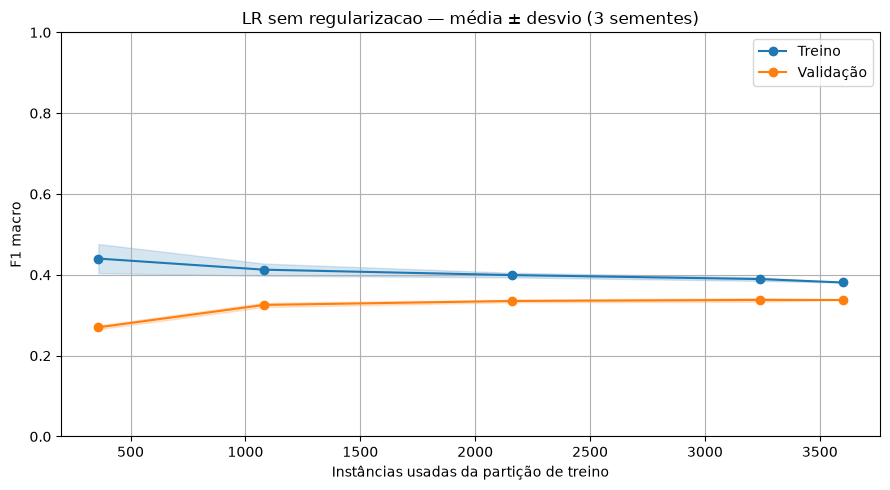

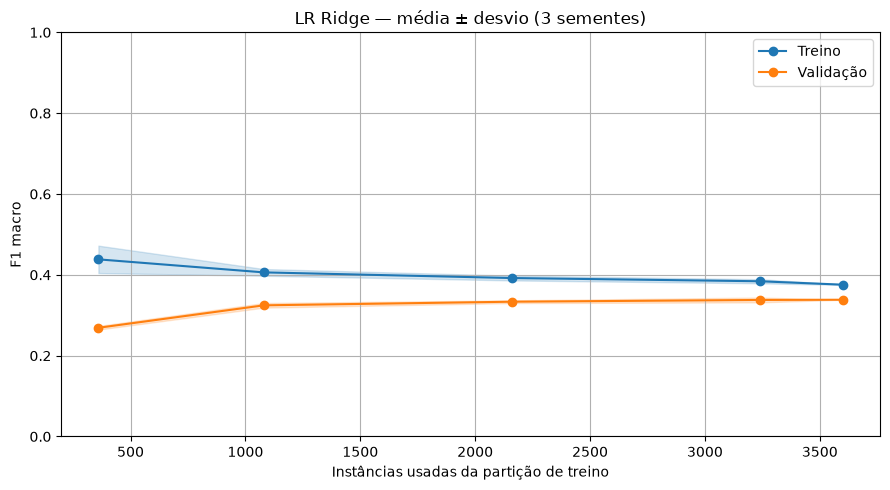

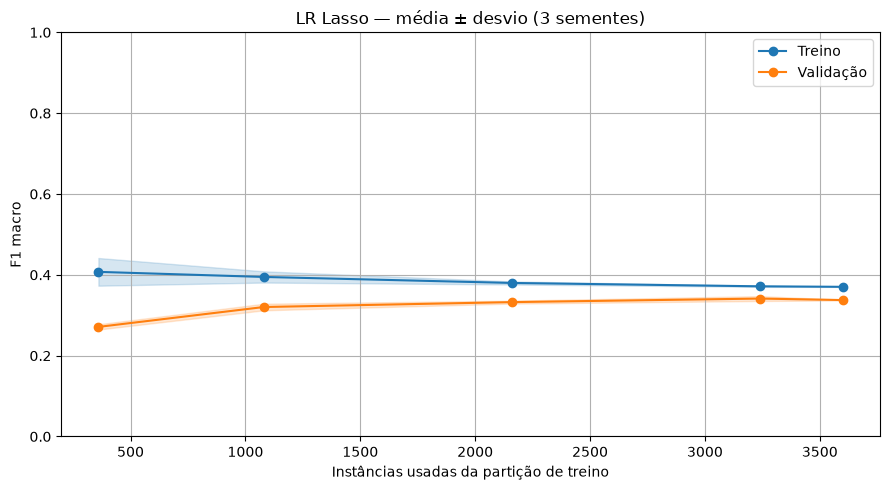

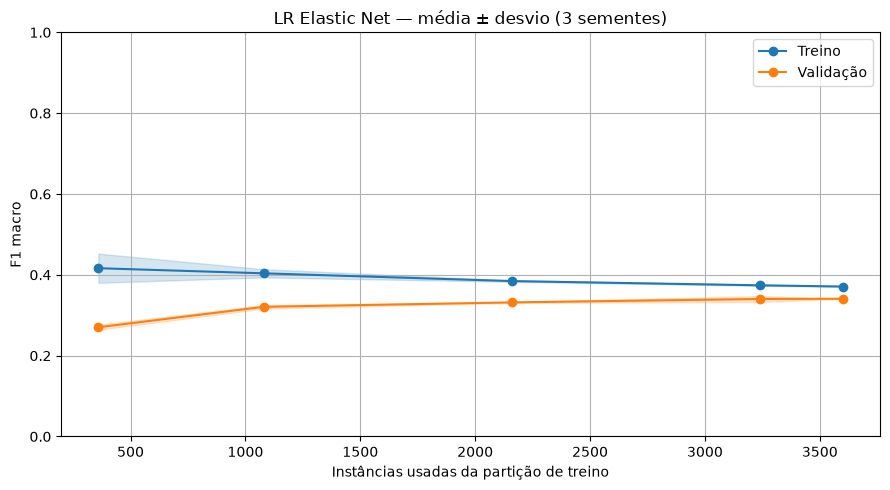

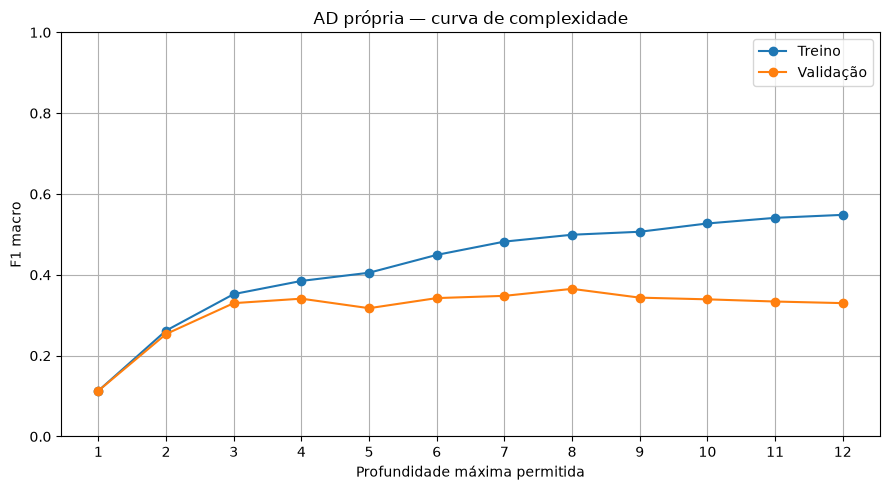

,max_depth,altura_real,nos,treino_f1_macro,validacao_f1_macro,gap_f1_macro
69,1.0,1.0,3.0,0.113179,0.113238,-0.000059
70,2.0,2.0,7.0,0.261979,0.253532,0.008447
71,3.0,3.0,15.0,0.352330,0.329951,0.022380
72,4.0,4.0,31.0,0.384923,0.341008,0.043915
73,5.0,5.0,61.0,0.405183,0.317450,0.087734
74,6.0,6.0,107.0,0.449323,0.342445,0.106878
75,7.0,7.0,171.0,0.482228,0.348013,0.134216
76,8.0,8.0,253.0,0.499203,0.365306,0.133897
77,9.0,9.0,347.0,0.506581,0.343532,0.163049
78,10.0,10.0,433.0,0.527113,0.339378,0.187735


In [ ]:
learning_plots = []
for index, family in enumerate(PENALTIES, start=1):
    subset = results[(results.experimento == 'curva_lr') & (results.familia == family)]
    aggregated = subset.groupby('n_treino')[['treino_f1_macro', 'validacao_f1_macro']].agg(['mean', 'std'])
    fig, ax = plt.subplots()
    x = aggregated.index.to_numpy()
    for column, label, color in [('treino_f1_macro', 'Treino', 'tab:blue'),
                                 ('validacao_f1_macro', 'Validação', 'tab:orange')]:
        mean = aggregated[column]['mean'].to_numpy()
        std = aggregated[column]['std'].to_numpy()
        ax.plot(x, mean, 'o-', label=label, color=color)
        ax.fill_between(x, mean - std, mean + std, alpha=0.18, color=color)
    ax.set(title=family + ' — média ± desvio (3 sementes)',
           xlabel='Instâncias usadas da partição de treino', ylabel='F1 macro', ylim=(0, 1))
    ax.legend(); fig.tight_layout()
    name = f'curva_{index}_lr.png'
    fig.savefig(FIG / name, dpi=150); learning_plots.append(name)
    plt.show()

tree_curve = results[results.experimento == 'curva_ad'].sort_values('max_depth')
fig, ax = plt.subplots()
ax.plot(tree_curve.max_depth, tree_curve.treino_f1_macro, 'o-', label='Treino')
ax.plot(tree_curve.max_depth, tree_curve.validacao_f1_macro, 'o-', label='Validação')
ax.set(title='Arvore de Decisão própria — curva de complexidade', xlabel='Profundidade máxima permitida',
       ylabel='F1 macro', ylim=(0, 1), xticks=range(1, MAX_DEPTH + 1))
ax.legend(); fig.tight_layout()
name = 'curva_5_ad.png'
fig.savefig(FIG / name, dpi=150); learning_plots.append(name)
plt.show()
assert len(learning_plots) == 5
display(tree_curve[['max_depth', 'altura_real', 'nos', 'treino_f1_macro', 'validacao_f1_macro', 'gap_f1_macro']])

## 9. Seleção de três modelos antes do teste

Seleção por relevância metodológica, não pelos três maiores escores no teste:

1. LR sem regularização, treinada com 100% do treino e semente 42: referência sem penalidade.
2. Melhor família regularizada pelo F1 macro médio de validação nas três sementes, também com 100% do treino; representada pela semente 42 (não escolhemos a melhor semente).
3. AD com maior F1 macro de validação na curva de profundidade; empate favorece a menor profundidade.

São três configurações representativas de desempenho, regularização e interpretabilidade. A escolha é registrada ANTES de qualquer avaliação de teste. Não se refaz treino incorporando validação, para preservar o protocolo 60/20/20.

In [10]:
lr_full = results[(results.experimento == 'curva_lr') & (results.fracao_treino == 1.0)]
rank_regularized = lr_full[lr_full.familia != 'LR sem regularizacao'].groupby('familia').validacao_f1_macro.mean().sort_values(ascending=False, kind='stable')
best_regularized = rank_regularized.index[0]
selected = [lr_full[(lr_full.familia == family) & (lr_full.semente == SEED)].iloc[0].modelo_id
            for family in ['LR sem regularizacao', best_regularized]]
selected.append(tree_curve.sort_values(['validacao_f1_macro', 'max_depth'], ascending=[False, True]).iloc[0].modelo_id)
assert len(set(selected)) == 3
selection = results[results.modelo_id.isin(selected)].copy()
selection['criterio'] = selection.familia.map({
    'LR sem regularizacao': 'referencia sem penalidade; treino 100%; seed 42',
    best_regularized: 'melhor familia regularizada pela media de validacao; treino 100%; seed 42',
    'AD propria': 'melhor profundidade na validacao; empate favorece menor altura'})
selection.to_csv(OUT / 'selecao_antes_teste.csv', index=False)
display(selection[['modelo_id', 'validacao_f1_macro', 'criterio']])
SELECTION_FROZEN = True

,modelo_id,validacao_f1_macro,criterio
19,curva_lr|LR sem regularizacao|seed=42|fraction...,0.338266,referencia sem penalidade; treino 100%; seed 42
22,curva_lr|LR Elastic Net|seed=42|fraction=1.0|d...,0.340766,melhor familia regularizada pela media de vali...
76,curva_ad|AD propria|seed=42|fraction=1.0|depth=8,0.365306,melhor profundidade na validacao; empate favor...


## 10. Avaliação final no teste de TODOS os casos

Somente agora transformamos e predizemos os 1.200 registros de teste. Avaliamos cada ponto/semente das quatro curvas LR, cada profundidade da AD e os casos adicionais de consistência. Não escolhemos modelos após ler estes escores.

Precision = TP/(TP+FP), recall = TP/(TP+FN), F1 = 2PR/(P+R). Macro é média não ponderada das classes; micro agrega contagens; weighted pondera pelo suporte. Em classificação multiclasse de rótulo único, micro precision = micro recall = micro F1 = accuracy. Divisão por zero usa 0, inclusive quando uma classe nunca é predita. Exportamos também relatórios por classe para TODOS os modelos, não apenas médias.

Baseline: predizer sempre a classe mais frequente no TREINO. Serve para contextualizar os resultados, não compõe os cinco gráficos.

In [11]:
assert SELECTION_FROZEN
X_test, y_test = test[FEATURES], test[TARGET].to_numpy()
test_rows, per_class, predictions = [], [], {}
for _, row in results.iterrows():
    key = row.modelo_id
    model, processor = fitted[key]
    pred = model.predict(processor.transform(X_test))
    predictions[key] = pred
    test_rows.append({'modelo_id': key, **metricas(y_test, pred)})
    report = classification_report(y_test, pred, labels=CLASSES, output_dict=True, zero_division=0)
    for label in CLASSES:
        per_class.append({'modelo_id': key, 'classe': label, **report[str(label)]})
test_metrics = results.merge(pd.DataFrame(test_rows), on='modelo_id', validate='one_to_one')
assert len(test_metrics) == len(results)
assert np.allclose(test_metrics.f1_micro, test_metrics.accuracy)
test_metrics.to_csv(OUT / 'metricas_teste_todos_casos.csv', index=False)
pd.DataFrame(per_class).to_csv(OUT / 'metricas_teste_por_classe.csv', index=False)
columns = ['familia', 'experimento', 'fracao_treino', 'max_depth', 'precision_macro', 'recall_macro', 'f1_micro', 'f1_macro']
# Mostrar TODAS as configurações de curvas; repetições resumidas por média.
display(test_metrics[test_metrics.experimento == 'curva_lr'].groupby(['familia', 'fracao_treino'])[
    ['precision_macro', 'recall_macro', 'f1_micro', 'f1_macro']].agg(['mean', 'std']))
display(test_metrics[test_metrics.experimento == 'curva_ad'][columns])
baseline = DummyClassifier(strategy='most_frequent').fit(np.zeros((len(train), 1)), y_train)
baseline_scores = metricas(y_test, baseline.predict(np.zeros((len(test), 1))))
pd.DataFrame([baseline_scores]).to_csv(OUT / 'baseline_teste.csv', index=False)
print('Baseline majoritário:'); display(pd.DataFrame([baseline_scores]))
display(test_metrics[test_metrics.modelo_id.isin(selected)][columns])

precision_macro           recall_macro  \
                                              mean       std         mean   
familia              fracao_treino                                          
LR Elastic Net       0.1                  0.287425  0.013925     0.278215   
                     0.3                  0.328492  0.023383     0.350044   
                     0.6                  0.355568  0.016421     0.376021   
                     0.9                  0.352667  0.008774     0.379654   
                     1.0                  0.360092  0.000710     0.385296   
LR Lasso             0.1                  0.289272  0.017225     0.278444   
                     0.3                  0.327299  0.025488     0.347895   
                     0.6                  0.353802  0.021009     0.374098   
                     0.9                  0.354929  0.006105     0.380888   
                     1.0                  0.360101  0.000085     0.382845   
LR Ridge             0.1                  0.287209  0.014445     0.278433   
                     0.3                  0.325912  0.018701     0.348332   
                     0.6                  0.357340  0.014449     0.376629   
                     0.9                  0.352287  0.008000     0.379591   
                     1.0                  0.347826  0.001527     0.378014   
LR sem regularizacao 0.1                  0.287584  0.013447     0.278999   
                     0.3                  0.324881  0.016066     0.349594   
                     0.6                  0.354751  0.014390     0.376114   
                     0.9                  0.352366  0.005878     0.380228   
                     1.0                  0.349133  0.000267     0.380896   

                                              f1_micro            f1_macro  \
                                         std      mean       std      mean   
familia              fracao_treino                                           
LR Elastic Net       0.1            0.009644  0.454722  0.015950  0.270538   
                     0.3            0.015027  0.496944  0.024386  0.322842   
                     0.6            0.009105  0.522500  0.016667  0.342003   
                     0.9            0.002941  0.526389  0.003758  0.344844   
                     1.0            0.000572  0.533889  0.000481  0.351285   
LR Lasso             0.1            0.009934  0.455833  0.017017  0.270718   
                     0.3            0.016694  0.494444  0.026462  0.319745   
                     0.6            0.010411  0.521111  0.017507  0.338539   
                     0.9            0.001893  0.530278  0.003368  0.345237   
                     1.0            0.000000  0.533333  0.000000  0.347995   
LR Ridge             0.1            0.009384  0.455000  0.016604  0.271119   
                     0.3            0.014509  0.494444  0.022948  0.322178   
                     0.6            0.007309  0.522222  0.014821  0.343328   
                     0.9            0.002168  0.525278  0.004194  0.346489   
                     1.0            0.000669  0.521111  0.000962  0.343621   
LR sem regularizacao 0.1            0.009041  0.455833  0.015298  0.271663   
                     0.3            0.014009  0.494722  0.022857  0.323377   
                     0.6            0.005509  0.519722  0.013238  0.343489   
                     0.9            0.000952  0.525278  0.002927  0.347494   
                     1.0            0.000218  0.522778  0.000481  0.347473   

                                              
                                         std  
familia              fracao_treino            
LR Elastic Net       0.1            0.009681  
                     0.3            0.012352  
                     0.6            0.009746  
                     0.9            0.004252  
                     1.0            0.000507  
LR Lasso             0.1            0.010214  
                     0.3            0.014207 

,familia,experimento,fracao_treino,max_depth,precision_macro,recall_macro,f1_micro,f1_macro
69,AD propria,curva_ad,1.0,1.0,0.079003,0.200000,0.391667,0.113211
70,AD propria,curva_ad,1.0,2.0,0.210145,0.336401,0.485833,0.256684
71,AD propria,curva_ad,1.0,3.0,0.286462,0.376689,0.487500,0.323266
72,AD propria,curva_ad,1.0,4.0,0.342777,0.349582,0.474167,0.326957
73,AD propria,curva_ad,1.0,5.0,0.393698,0.388586,0.507500,0.363970
74,AD propria,curva_ad,1.0,6.0,0.403764,0.405925,0.518333,0.389724
75,AD propria,curva_ad,1.0,7.0,0.408360,0.409648,0.509167,0.401044
76,AD propria,curva_ad,1.0,8.0,0.385429,0.398038,0.486667,0.387598
77,AD propria,curva_ad,1.0,9.0,0.381361,0.386465,0.470833,0.377606
78,AD propria,curva_ad,1.0,10.0,0.381911,0.387217,0.462500,0.379489


Baseline majoritário:


,accuracy,precision_micro,recall_micro,f1_micro,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,0.220833,0.220833,0.220833,0.220833,0.022083,0.1,0.036177,0.048767,0.220833,0.079892


,familia,experimento,fracao_treino,max_depth,precision_macro,recall_macro,f1_micro,f1_macro
19,LR sem regularizacao,curva_lr,1.0,NaN,0.348979,0.380770,0.522500,0.347384
22,LR Elastic Net,curva_lr,1.0,NaN,0.359399,0.384776,0.533333,0.350849
76,AD propria,curva_ad,1.0,8.0,0.385429,0.398038,0.486667,0.387598


## 11. Três matrizes de confusão e análise de erros

Para os três modelos congelados, mostramos contagens absolutas com o mesmo eixo/ordem de classes. Também exportamos matrizes normalizadas por linha (recall de cada classe) e listamos as confusões fora da diagonal mais frequentes. O maior número de erros absolutos pode refletir uma classe maior; por isso analisamos também recall por classe. Não interpretamos essas diferenças como causalidade.

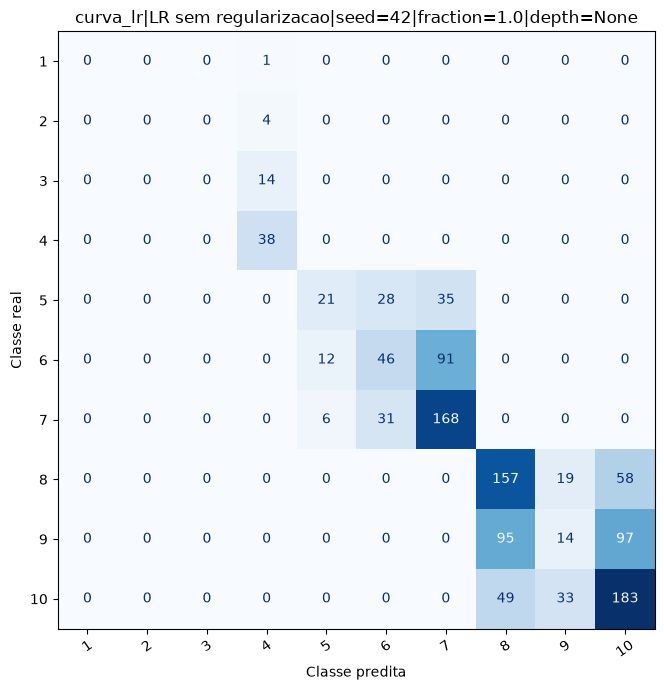

Principais confusões (quantidade, real, predita): [(97, '9', '10'), (95, '9', '8'), (91, '6', '7')]


,classe,recall,suporte
0,1,0.000000,1
1,2,0.000000,4
2,3,0.000000,14
3,4,1.000000,38
4,5,0.250000,84
5,6,0.308725,149
6,7,0.819512,205
7,8,0.670940,234
8,9,0.067961,206
9,10,0.690566,265


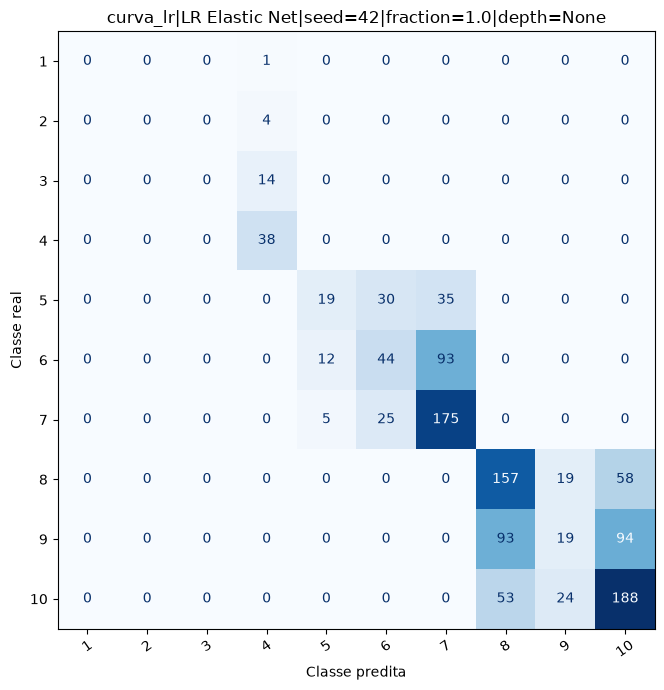

Principais confusões (quantidade, real, predita): [(94, '9', '10'), (93, '9', '8'), (93, '6', '7')]


,classe,recall,suporte
0,1,0.000000,1
1,2,0.000000,4
2,3,0.000000,14
3,4,1.000000,38
4,5,0.226190,84
5,6,0.295302,149
6,7,0.853659,205
7,8,0.670940,234
8,9,0.092233,206
9,10,0.709434,265


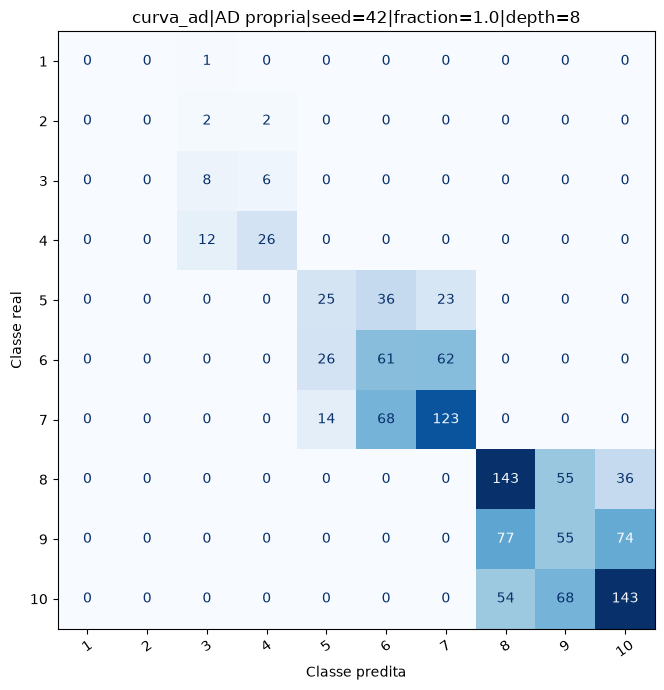

Principais confusões (quantidade, real, predita): [(77, '9', '8'), (74, '9', '10'), (68, '7', '6')]


,classe,recall,suporte
0,1,0.000000,1
1,2,0.000000,4
2,3,0.571429,14
3,4,0.684211,38
4,5,0.297619,84
5,6,0.409396,149
6,7,0.600000,205
7,8,0.611111,234
8,9,0.266990,206
9,10,0.539623,265


In [12]:
error_summaries = []
for index, key in enumerate(selected, start=1):
    matrix = confusion_matrix(y_test, predictions[key], labels=CLASSES)
    assert matrix.shape == (len(CLASSES), len(CLASSES)) and matrix.sum() == len(test)
    normalized = np.divide(matrix, matrix.sum(axis=1, keepdims=True),
                           out=np.zeros_like(matrix, dtype=float), where=matrix.sum(axis=1, keepdims=True) != 0)
    pd.DataFrame(matrix, index=CLASSES, columns=CLASSES).to_csv(OUT / f'confusao_{index}_contagens.csv')
    pd.DataFrame(normalized, index=CLASSES, columns=CLASSES).to_csv(OUT / f'confusao_{index}_normalizada.csv')
    fig, ax = plt.subplots(figsize=(10, 7))
    ConfusionMatrixDisplay(matrix, display_labels=CLASSES).plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=35)
    ax.set_title(key); ax.set_xlabel('Classe predita'); ax.set_ylabel('Classe real')
    ax.grid(False); fig.tight_layout()
    fig.savefig(FIG / f'matriz_confusao_{index}.png', dpi=150)
    plt.show()
    error_pairs = sorted([(int(matrix[i, j]), str(CLASSES[i]), str(CLASSES[j]))
                          for i in range(len(CLASSES)) for j in range(len(CLASSES)) if i != j and matrix[i, j] > 0], reverse=True)
    top = error_pairs[:3]
    recalls = dict(zip(CLASSES.tolist(), np.diag(normalized).tolist()))
    error_summaries.append({'modelo_id': key, 'principais_erros': top, 'recall_por_classe': recalls})
    print('Principais confusões (quantidade, real, predita):', top)
    display(pd.DataFrame({'classe': CLASSES, 'recall': np.diag(normalized), 'suporte': matrix.sum(axis=1)}))
# Exportar predições dos três selecionados para auditoria individual.
prediction_table = test[['respondent_id', TARGET]].copy()
for index, key in enumerate(selected, start=1):
    prediction_table[f'predicao_modelo_{index}'] = predictions[key]
prediction_table.to_csv(OUT / 'predicoes_selecionados.csv', index=False)

## 12. Discussão baseada na execução e limitações

A seção seguinte gera o relatório com números da execução real. A maior prioridade é comparar F1 macro com o baseline e os recalls das classes raras, não somente micro F1. Uma curva crescente de treino sem ganho na validação aponta sobreajuste; não é justificativa para manipular classes ou fabricar texto.

Limitações adicionais: holdout único; apenas três repetições de amostragem; hiperparâmetros fixos sem otimização; SGD com orçamento finito sem alegação de convergência garantida; alvo contemporâneo; campos categóricos repetitivos; fonte/licença não informadas; nenhuma conclusão sobre todos os fãs de GTA VI. Mais dados sem sinal adicional podem não melhorar generalização.

In [13]:
selected_metrics = test_metrics.set_index('modelo_id').loc[selected]
lines = ['# Resultados da execução — GTA VI', '',
         '## Aderência',
         f'Adaptação ao CSV: {len(df)} registros e {len(CLASSES)} classes nativas de {TARGET} (notas de 1 a 10). '
         'NÃO há texto livre; TF-IDF aplicado às dez descrições categóricas de most_anticipated_feature. '
         'overall_sentiment possui três classes, não cinco. Aprovação do professor ou dados textuais reais '
         'ainda são necessários para aderência literal. A nota 1 tem dois registros: um no treino e outro no teste, sem suporte na validação. F1 macro considera todas as dez classes.', '',
         '## Protocolo',
         f'Treino={len(train)}; validação={len(val)}; teste={len(test)}. '
         f'Sementes={SEEDS}; épocas SGD={EPOCHS}; altura limite AD={MAX_DEPTH}. '
         f'{len(results)} configurações avaliadas; cinco curvas; três matrizes de confusão.', '',
         'Consistência: 1.080, 2.160 e 3.240 registros; três repetições por algoritmo/tamanho. '
         'Subconjuntos aninhados, pré-processamento ajustado em cada subconjunto, teste fora da seleção.', '',
         '## Métricas dos três modelos selecionados',
         '|Modelo|Precision macro|Recall macro|F1 micro|F1 macro|Gap treino-validação|',
         '|---|---:|---:|---:|---:|---:|']
for key, row in selected_metrics.iterrows():
    safe_key = key.replace('|', '&#124;')
    lines.append(f'|{safe_key}|{row.precision_macro:.4f}|{row.recall_macro:.4f}|{row.f1_micro:.4f}|{row.f1_macro:.4f}|{row.gap_f1_macro:.4f}|')
lines += ['', f'Baseline majoritário: F1 micro={baseline_scores["f1_micro"]:.4f}; '
          f'F1 macro={baseline_scores["f1_macro"]:.4f}.', '', '## Interpretação das curvas']
for family in PENALTIES:
    curve = results[(results.experimento == 'curva_lr') & (results.familia == family)]
    first = curve[curve.fracao_treino == min(FRACTIONS)].validacao_f1_macro.mean()
    last = curve[curve.fracao_treino == 1].validacao_f1_macro.mean()
    lines.append(f'- {family}: validação média F1 macro de {first:.4f} (360 exemplos) para {last:.4f} (3.600), diferença {last-first:+.4f}.')
lines += [f'- AD: F1 macro de treino {tree_curve.iloc[0].treino_f1_macro:.4f} → {tree_curve.iloc[-1].treino_f1_macro:.4f}; '
          f'validação {tree_curve.iloc[0].validacao_f1_macro:.4f} → {tree_curve.iloc[-1].validacao_f1_macro:.4f} '
          'entre profundidades 1 e 12. Comparar com a profundidade selecionada, não escolher pela maior altura.', '',
          '## Consistência', summary.to_csv(index=False),
          'O desvio apresentado é entre três amostragens do mesmo holdout, não intervalo de confiança nem prova de significância.', '',
          '## Erros dos selecionados']
for item in error_summaries:
    lines += [f'### {item["modelo_id"]}',
              'Confusões principais: ' + '; '.join(f'{real} → {pred}: {count}' for count, real, pred in item['principais_erros']),
              'Recall por classe: ' + '; '.join(f'{k}={v:.4f}' for k, v in item['recall_por_classe'].items()), '']
lines += ['## Conclusão',
          'Os números acima medem associação contemporânea das respostas com a nota de hype. Não demonstram análise de sentimento em texto livre. '
          'Acurácia/micro F1 devem ser lidos com macro F1 e recalls; a classe majoritária pode dominar. '
          'Regularização e mais amostras não garantem melhora. Os escores de teste não foram usados para selecionar os três modelos.', '',
          '## Reprodutibilidade', json.dumps(VERSIONS, indent=2), '',
          'Consultar README.md da documentação para execução, método, artefatos e pendências de aderência.']
report_text = '\n'.join(lines)
(OUT / 'relatorio_resultados.md').write_text(report_text, encoding='utf-8')
manifest = {'dataset': str(DATASET.relative_to(ROOT)),
            'dataset_sha256': hashlib.sha256(DATASET.read_bytes()).hexdigest(),
            'shape': list(df.shape), 'target': TARGET, 'classes': CLASSES.tolist(),
            'genuine_unstructured_text': False, 'full_assignment_compliance': False,
            'split_sizes': {'train': len(train), 'validation': len(val), 'test': len(test)},
            'seeds': SEEDS, 'fractions': FRACTIONS, 'epochs': EPOCHS,
            'tree_depth_limit': MAX_DEPTH, 'configurations': len(results),
            'learning_plots': learning_plots, 'selected_model_ids': selected,
            'selection_uses_test': False, 'features': FEATURES,
            'rare_class_policy': 'um registro por classe com menos de tres exemplos no treino; restante no teste',
            'validation_missing_classes': sorted(set(CLASSES.tolist()) - set(val[TARGET].tolist())),
            'versions': VERSIONS}
(OUT / 'manifesto.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
display(Markdown(report_text))
print('Artefatos gravados em:', OUT)

# Resultados da execução — GTA VI

## Aderência
Adaptação ao CSV: 6000 registros e 10 classes nativas de hype_score_1to10 (notas de 1 a 10). NÃO há texto livre; TF-IDF aplicado às dez descrições categóricas de most_anticipated_feature. overall_sentiment possui três classes, não cinco. Aprovação do professor ou dados textuais reais ainda são necessários para aderência literal. A nota 1 tem dois registros: um no treino e outro no teste, sem suporte na validação. F1 macro considera todas as dez classes.

## Protocolo
Treino=3600; validação=1200; teste=1200. Sementes=[42, 43, 44]; épocas SGD=160; altura limite AD=12. 81 configurações avaliadas; cinco curvas; três matrizes de confusão.

Consistência: 1.080, 2.160 e 3.240 registros; três repetições por algoritmo/tamanho. Subconjuntos aninhados, pré-processamento ajustado em cada subconjunto, teste fora da seleção.

## Métricas dos três modelos selecionados
|Modelo|Precision macro|Recall macro|F1 micro|F1 macro|Gap treino-validação|
|---|---:|---:|---:|---:|---:|
|curva_lr&#124;LR sem regularizacao&#124;seed=42&#124;fraction=1.0&#124;depth=None|0.3490|0.3808|0.5225|0.3474|0.0427|
|curva_lr&#124;LR Elastic Net&#124;seed=42&#124;fraction=1.0&#124;depth=None|0.3594|0.3848|0.5333|0.3508|0.0299|
|curva_ad&#124;AD propria&#124;seed=42&#124;fraction=1.0&#124;depth=8|0.3854|0.3980|0.4867|0.3876|0.1339|

Baseline majoritário: F1 micro=0.2208; F1 macro=0.0362.

## Interpretação das curvas
- LR sem regularizacao: validação média F1 macro de 0.2701 (360 exemplos) para 0.3378 (3.600), diferença +0.0677.
- LR Ridge: validação média F1 macro de 0.2690 (360 exemplos) para 0.3384 (3.600), diferença +0.0694.
- LR Lasso: validação média F1 macro de 0.2712 (360 exemplos) para 0.3376 (3.600), diferença +0.0664.
- LR Elastic Net: validação média F1 macro de 0.2703 (360 exemplos) para 0.3409 (3.600), diferença +0.0706.
- AD: F1 macro de treino 0.1132 → 0.5484; validação 0.1132 → 0.3300 entre profundidades 1 e 12. Comparar com a profundidade selecionada, não escolher pela maior altura.

## Consistência
familia,fracao_treino,n_treino,treino_media,validacao_media,validacao_desvio,validacao_min,validacao_max,gap_medio
AD propria,0.3,1080,0.5278515541690827,0.35631033790074684,0.011490171661578895,0.34315322160239564,0.3643693563993734,0.17154121626833585
AD propria,0.6,2160,0.5180187941496192,0.37131812219168564,0.019415415931016932,0.3525447844131432,0.39131750596754217,0.14670067195793363
AD propria,0.9,3240,0.49636713454646325,0.3693698063063042,0.007340290645670081,0.36220976658028253,0.37687796059983736,0.12699732824015905
LR Ridge,0.3,1080,0.4060720731301826,0.32453290560583087,0.00573757415245602,0.31809696150045497,0.32911239326962627,0.08153916752435177
LR Ridge,0.6,2160,0.3920722171723096,0.3335178669335351,0.003377426369711347,0.3298493174796918,0.3364981423416743,0.05855435023877446
LR Ridge,0.9,3240,0.38408419931558674,0.3378226064047692,0.006007149029651485,0.3315788358405064,0.34356123323318993,0.046261592910817495

O desvio apresentado é entre três amostragens do mesmo holdout, não intervalo de confiança nem prova de significância.

## Erros dos selecionados
### curva_lr|LR sem regularizacao|seed=42|fraction=1.0|depth=None
Confusões principais: 9 → 10: 97; 9 → 8: 95; 6 → 7: 91
Recall por classe: 1=0.0000; 2=0.0000; 3=0.0000; 4=1.0000; 5=0.2500; 6=0.3087; 7=0.8195; 8=0.6709; 9=0.0680; 10=0.6906

### curva_lr|LR Elastic Net|seed=42|fraction=1.0|depth=None
Confusões principais: 9 → 10: 94; 9 → 8: 93; 6 → 7: 93
Recall por classe: 1=0.0000; 2=0.0000; 3=0.0000; 4=1.0000; 5=0.2262; 6=0.2953; 7=0.8537; 8=0.6709; 9=0.0922; 10=0.7094

### curva_ad|AD propria|seed=42|fraction=1.0|depth=8
Confusões principais: 9 → 8: 77; 9 → 10: 74; 7 → 6: 68
Recall por classe: 1=0.0000; 2=0.0000; 3=0.5714; 4=0.6842; 5=0.2976; 6=0.4094; 7=0.6000; 8=0.6111; 9=0.2670; 10=0.5396

## Conclusão
Os números acima medem associação contemporânea das respostas com a nota de hype. Não demonstram análise de sentimento em texto livre. Acurácia/micro F1 devem ser lidos com macro F1 e recalls; a classe majoritária pode dominar. Regularização e mais amostras não garantem melhora. Os escores de teste não foram usados para selecionar os três modelos.

## Reprodutibilidade
{
  "python": "3.14.4",
  "numpy": "2.5.2",
  "pandas": "3.0.5",
  "scikit_learn": "1.9.0",
  "scipy": "1.18.1"
}

Consultar README.md da documentação para execução, método, artefatos e pendências de aderência.

Artefatos gravados em: /home/development/personal/Learning/AI/TL_AI-MachineLearning/docs/gta6_classificacao/resultados


## Checklist final do enunciado

|Requisito|Situação|
|---|---|
|Ao menos 2.000 instâncias|Verificado: 6.000|
|Ao menos cinco classes|Verificado: dez notas originais de hype_score_1to10|
|Texto não estruturado genuíno|**Não atendido pelo CSV**; somente frases categóricas|
|TF-IDF|Implementado nas descrições originais, com ressalva acima|
|60% treino / 20% validação / 20% teste|Verificado com IDs disjuntos; nota 1 sem suporte na validação|
|Estudo introdutório|Tipos, ausências, cardinalidades, distribuição e estatísticas|
|LR-GD|SGD com perda logística, OvR; confirmar se GD em lote for obrigatório|
|AD treino e predição próprios|CART/Gini implementada integralmente neste notebook|
|Consistência 30/60/90% do treino|Ambos algoritmos; subconjuntos pareados e três sementes|
|Cinco curvas|Quatro LR por tamanho; AD por profundidade até limite 12|
|Precision, recall, F1 micro/macro no teste|Todos os pontos/sementes; também relatórios por classe|
|Três matrizes de confusão|Seleção por validação e relevância, antes do teste|
|Documentação|docs/gta6_classificacao/README.md e resultados/relatorio_resultados.md|

Este checklist NÃO afirma aderência total: a lacuna textual é real e não pode ser solucionada só com pré-processamento.